# House Size vs. Price — Complete Linear Regression Project

> **Project scope and honest limitations**
>
> This notebook goes beyond data ingestion and exploratory data analysis (EDA). It includes the full beginner-level scikit-learn workflow: define features and target, split data into training/testing sets, fit a linear-regression model, make predictions, evaluate MAE/RMSE/R², compare against a baseline, inspect residuals, generate new predictions, and save/reload the trained model.
>
> **Important next step addressed here:** the size-versus-price scatter plot is essential for checking whether a straight-line model is plausible. Step 4.3 now includes a fitted trend line so you can inspect the pattern before training.
>
> **Be candid about the data:** this is a teaching dataset, not verified real-estate market data. A strong size-price relationship in a synthetic dataset demonstrates the algorithm; it does not prove that size alone predicts real Indian house prices reliably. Location, age, condition, amenities and many other factors affect real prices. Always interpret the charts and metrics produced by your own run rather than assuming example numbers are universal.

## Project workflow

1. Load and inspect the CSV.
2. Explore individual columns and the relationship between size and price.
3. Prepare `X` (house size) and `y` (house price).
4. Split into training and testing data.
5. Train a scikit-learn linear-regression pipeline.
6. Evaluate predictions against a baseline and inspect residuals.
7. Predict for new sizes and save/reload the model.

---


## Step 1 — Pack our toolbox (import libraries)

**What the code does:** Each `import` line brings a *library* (a ready-made toolbox of code that other people wrote) into our notebook:
- `pandas` (nicknamed `pd`) handles tables of data.
- `numpy` (nicknamed `np`) does maths on lots of numbers very fast.
- `seaborn` (`sns`) and `matplotlib.pyplot` (`plt`) draw charts.
- `Path` (from the `pathlib` library) helps us write file addresses safely.
- `sns.set_theme(style="whitegrid")` gives all our charts a clean look with light grid lines.

**An everyday picture:** Before baking a cake you put the bowl, the whisk and the tray on the table. Nothing is baked yet. You have only got your tools ready.

**Why we need it:** Python on its own only knows the basics. These toolboxes do the heavy lifting for tables, maths and pictures, so we do not have to build them from scratch.

**How it works (the simple idea):** `import pandas as pd` means "go and fetch the pandas toolbox, and let me call it `pd` for short", just like calling your friend Alexander "Alex".

In [66]:
# Libraries:
import pandas as pd              # pandas = our table tool (like a super-powered spreadsheet)
import numpy as np               # numpy = our fast-maths tool for lots of numbers
import seaborn as sns            # seaborn = a tool for colourful charts
import matplotlib.pyplot as plt  # matplotlib = a tool for drawing plain, clear charts

# pathlib helps us work with file addresses in a clear and reliable way.
from pathlib import Path

# Give all our charts a clean look with light grid lines.
sns.set_theme(style="whitegrid")

#### What we see and what we learn (Step 1)

**Observation:** This cell prints nothing. If you run it and no red error message appears, it worked.

**Conclusion:** The toolbox is on the table. Next we need to meet our data and open it.

## Step 2 — Where does our data come from, and how do we load it?

**The address (path) of the data file:**
`/content/house_size_price_linear_dataset.csv`

- A *path* (the address of a file, like a street address for a house) tells the computer where to look.
- `/content` is the main folder on the temporary computer that Google Colab gives us in the cloud. You put the file there by uploading it.
- `house_size_price_linear_dataset.csv` is the file name. `.csv` means *comma-separated values*: a plain text file where every line is one row of a table and the values are separated by commas.

**Where does it come from?** Someone created this file and you uploaded it into Colab. The notebook does not say who made the data or how. The word "linear" in the file name hints that it was made so that price follows a straight line as size grows, but we will check that with our own eyes instead of just believing the name.

**What does it contain?** A small list of **200 houses** with just **2 columns**:
- `Size_in_SqFt`: how big the house is, in square feet.
- `Price_in_Lakhs`: how much it costs, in *lakhs* of rupees (one lakh is 100,000 rupees).

**An everyday picture:** A short catalogue of 200 homes for sale, where each line only says "how big" and "how much".

**What the code does:**
1. `DATA_PATH` stores the address of the file.
2. `DATA_PATH.exists()` asks "is there really a file at this address?" If not, the code stops and shows a friendly message.
3. `pd.read_csv(...)` reads the file into a `DataFrame` (a table with rows going across and columns going down, like a spreadsheet) that we name `df`.
4. `df.shape` tells us the size as *(number of rows, number of columns)*, and `df.head()` shows the first five rows.

**Why we need it:** Before we do anything clever we must be sure the file is there and can be read. If the file is missing, every later step would crash with confusing messages.

**How it works (the simple idea):** `read_csv` reads the text line by line, cuts each line at the commas and arranges the pieces in a grid. The first line becomes the column names.

In [67]:
# DATA_PATH is the address of our file, like a home address for the data.
DATA_PATH = Path("/content/house_size_price_linear_dataset.csv")

# Safety check: if nothing lives at this address, stop and show a helpful message.
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find the CSV file here: {DATA_PATH}\n"
        "Please upload the file to Colab or edit DATA_PATH so it points to your CSV file."
    )

# read_csv opens the file and turns it into a table. We keep that table in a box called df.
df = pd.read_csv(DATA_PATH)

# Tell us it worked, show the size of the table as (rows, columns), and show the first 5 rows.
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Number of rows and columns: (200, 2)


,Size_in_SqFt,Price_in_Lakhs
0,500,22.94
1,515,12.56
2,530,27.26
3,545,29.16
4,560,10.00


#### What we see and what we learn (Step 2)

**Observation:** Confirm that the success message appears and check the printed row/column count and first five rows. The expected teaching file has 200 rows and the two columns `Size_in_SqFt` and `Price_in_Lakhs`; if your output differs, use the actual output and investigate before continuing.

**Conclusion:** The data is loaded. Next, check the column names, data types, missing values and numerical ranges rather than assuming the CSV is correct.


## Step 3 — Get to know our data

**What the code does:** A few quick check-ups:
1. `df.tail()` shows the **last** five rows (as `head()` showed the first five).
2. `df.columns.tolist()` lists the names of the columns.
3. `df.dtypes` shows the *data type* (the kind of value stored). `int64` means whole numbers and `float64` means numbers with decimals.
4. `df.isnull().sum()` counts *missing values* (empty cells) in each column.
5. `df.describe()` gives a "report card" for the number columns:
   - `count` = how many values there are,
   - `mean` = the average,
   - `std` (standard deviation) = how far values usually wander away from the average,
   - `min` and `max` = the smallest and the biggest value,
   - `25%`, `50%`, `75%` (quartiles) = the values a quarter, half and three-quarters of the way along when everything is lined up from smallest to biggest. The `50%` value is the middle one, also called the *median*.

**An everyday picture:** Before borrowing a library book you look at the last page, read the contents, and check for torn or missing pages.

**Why we need it:** A model can only learn from good data. One empty cell or a wrongly typed number could break the training, so we check first.

**How it works (the simple idea):** pandas has ready-made "check-up" commands. For example, `isnull()` puts a tick on every empty cell and `sum()` counts the ticks in each column.

#### 3a — The last five rows

In [68]:
# tail() = the LAST 5 rows (head() gave us the first 5).
display(df.tail())

,Size_in_SqFt,Price_in_Lakhs
195,3440,86.83
196,3455,99.52
197,3470,91.59
198,3485,95.08
199,3500,94.19


#### 3b — The names of the columns

In [69]:
# .columns = the labels along the top of the table; .tolist() turns them into a plain list.
print("Column names:")
print(df.columns.tolist())

Column names:
['Size_in_SqFt', 'Price_in_Lakhs']


#### 3c — The kind of value in each column

In [70]:
# dtypes = the kind of value in each column: int64 (whole number), float64 (decimal), object (text).
display(df.dtypes)

,0
Size_in_SqFt,int64
Price_in_Lakhs,float64


#### 3d — Counting empty cells

In [71]:
# isnull() marks every empty cell; sum() counts the marks in each column.
display(df.isnull().sum())

,0
Size_in_SqFt,0
Price_in_Lakhs,0


#### 3e — The report card for the number columns

In [72]:
# describe() = a report card (count, mean, std, min, quartiles, max) for the number columns.
display(df.describe())

,Size_in_SqFt,Price_in_Lakhs
count,200.000000,200.000000
mean,2000.000000,57.774600
std,872.553867,22.928822
min,500.000000,10.000000
25%,1250.250000,39.482500
50%,2000.000000,55.625000
75%,2749.750000,75.862500
max,3500.000000,105.900000


#### What we see and what we learn (Step 3)

**Observation:**
- The last rows are 3,440 to 3,500 sq ft with prices of 86.83, 99.52, 91.59, 95.08 and 94.19 lakh. So the rows are lined up from the smallest house to the biggest, and the biggest house is 3,500 sq ft.
- There are exactly **2 columns**: `Size_in_SqFt` (whole numbers) and `Price_in_Lakhs` (decimals).
- Missing values: **0 in both columns**. No cell is empty.
- Size goes from **500 to 3,500** sq ft with an average and a middle value both equal to **2,000**.
- Price goes from **10 to 105.9** lakh with an average of about **57.77** and a middle value (median) of about **55.63**. Half of the houses cost between about **39.48** and **75.86** lakh.

**Conclusion:** The data is complete and has no empty cells, so we do not need to clean anything. These numbers only *describe* the data. To see whether size and price are connected, we need pictures, and that is the next step.

## Step 4 — Draw pictures of the data

Numbers are good, but pictures show patterns much faster. Here we draw six kinds of charts.

### Step 4.1 — Histograms: how are sizes and prices spread out?

**What the code does:** It draws two *histograms* (bar charts that sort numbers into "bins", which are buckets, and show how many houses fall in each bucket). `bins=15` means 15 buckets, and `kde=True` adds a smooth line that follows the tops of the bars.

**An everyday picture:** Sorting a bag of coins into 15 jars by size, then looking at how full each jar is.

**Why we need it:** It shows the *whole shape* of each column, not only the average. We can see where most houses are and whether there are strange gaps.

**How it works (the simple idea):** The computer cuts the range (for sizes, 500 to 3,500) into 15 equal slices, counts the houses in each slice and draws a bar that tall.

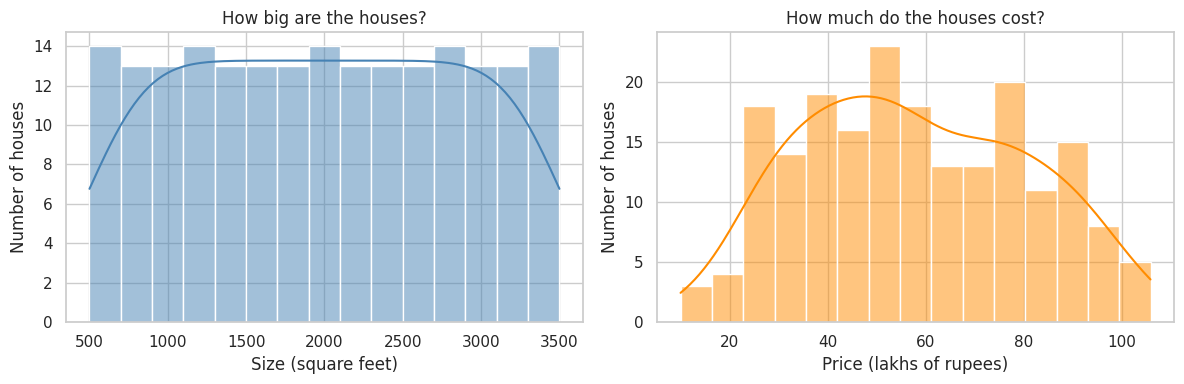

In [73]:
# Two histograms side by side: a histogram sorts numbers into buckets ("bins") and shows how many fall in each.
fig, axes = plt.subplots(1, 2, figsize=(12, 4)) #(1,2 ...) --> 2 columns in 1 row, (12,4) -> 12 units wide, 4 units tall

sns.histplot(df["Size_in_SqFt"], bins=15, kde=True, color="steelblue", ax=axes[0]) #axes[0]--> left frame
axes[0].set_title("How big are the houses?")        #sets title
axes[0].set_xlabel("Size (square feet)")            #labels x-axis
axes[0].set_ylabel("Number of houses")              #labels y-axis

sns.histplot(df["Price_in_Lakhs"], bins=15, kde=True, color="darkorange", ax=axes[1]) #axes[1]--> right frame
axes[1].set_title("How much do the houses cost?")   #sets title
axes[1].set_xlabel("Price (lakhs of rupees)")       #labels x-axis
axes[1].set_ylabel("Number of houses")              #labels y-axis

plt.tight_layout()
plt.show()

#### What we see and what we learn (Step 4.1)

**Observation:** The size bars are almost all the same height, about 13 to 14 houses each. That means the sizes are spread perfectly evenly from 500 to 3,500 sq ft. The price bars make a hump: most houses cost between about 25 and 80 lakh, the tallest bar is near 50 lakh (about 23 houses), and there are few houses at the very cheap end (below 20 lakh) and the very expensive end (above 100 lakh).

**Conclusion:** The sizes were laid out evenly, and the prices are bunched in the middle. There are no strange gaps. Next we check for unusual values.

### Step 4.2 — Box plots: the middle and the spread

**What the code does:** It draws one *box plot* for size and one for price. The box covers the middle half of the houses, the line inside the box is the *median* (the middle value), and the thin lines (*whiskers*) reach out to the smallest and biggest normal values. A dot beyond a whisker would mark an *outlier* (a value far away from all the others).

**An everyday picture:** The heights of children in a class drawn as a box: the middle child is the line, and the shortest and tallest children are at the ends of the whiskers.

**Why we need it:** Outliers (like a house priced at 5,000 lakh by mistake) can pull a model's line in the wrong direction. A box plot shows them right away.

**How it works (the simple idea):** The computer sorts the values, finds the middle value and the values a quarter and three-quarters of the way along, then draws them as a box with whiskers.

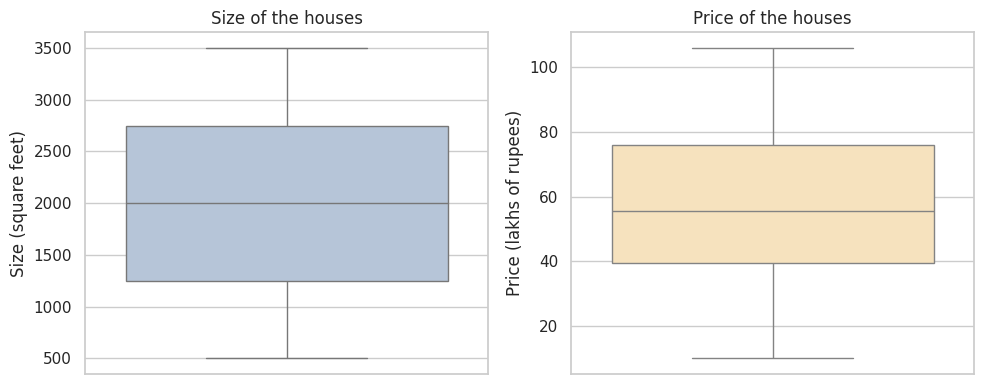

In [74]:
# Box plots: the box covers the middle half of the values, the line inside is the median (middle value),
# and the thin "whiskers" reach out to the smallest and biggest normal values.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(y=df["Size_in_SqFt"], color="lightsteelblue", ax=axes[0])
axes[0].set_title("Size of the houses")
axes[0].set_ylabel("Size (square feet)")

sns.boxplot(y=df["Price_in_Lakhs"], color="moccasin", ax=axes[1])
axes[1].set_title("Price of the houses")
axes[1].set_ylabel("Price (lakhs of rupees)")

plt.tight_layout()
plt.show()

#### What we see and what we learn (Step 4.2)

**Observation:** The size box runs from about 1,250 to 2,750 sq ft with the median line at 2,000, and the whiskers reach 500 and 3,500. The price box runs from about 39 to 76 lakh with the median near 56, and the whiskers reach 10 and about 106. There are **no dots beyond the whiskers**, so no outliers.

**Conclusion:** No house has a strange, extreme size or price, so we can keep all 200 houses. Now for the main question: is price connected to size?

### Step 4.2b — Violin plots: the box plot plus the shape

**What the code does:** It draws a *violin plot* for size and one for price. A violin plot is a box plot with a smooth outline wrapped around it. The outline is wide where many houses have that value and thin where few do. The small box inside is the same box plot we just saw.

**An everyday picture:** Think of a pile of sand poured through a funnel and viewed from the side. The pile is wide where there is a lot of sand and narrow at the top and the bottom.

**Why we need it:** A box plot only shows five summary numbers. Two very different groups of houses can give the same box. The violin shows the whole shape, for example whether the prices bunch up in one place or in two.

**How it works (the simple idea):** The computer estimates how crowded each value is (the same idea as the smooth curve on the histograms in Step 4.1), mirrors that curve on both sides, and puts the box plot inside it.

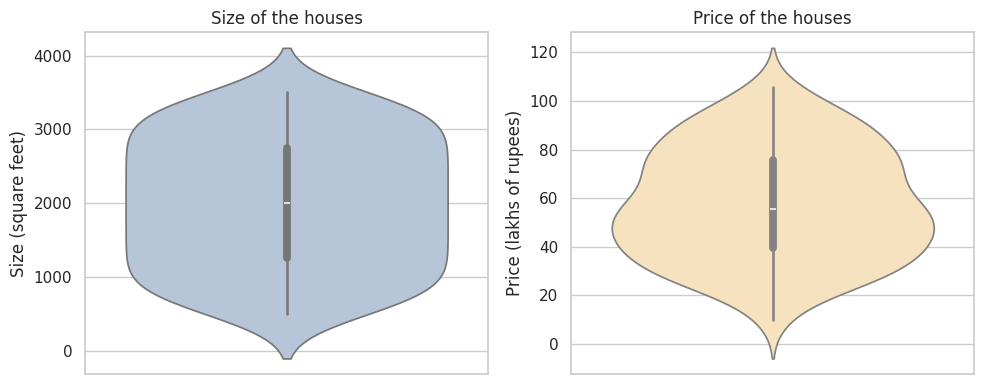

In [75]:
# Violin plots: the outline is wide where many houses have that value, thin where few do.
# The small box inside is the same box plot we drew before.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.violinplot(y=df["Size_in_SqFt"], color="lightsteelblue", inner="box", ax=axes[0])
axes[0].set_title("Size of the houses")
axes[0].set_ylabel("Size (square feet)")

sns.violinplot(y=df["Price_in_Lakhs"], color="moccasin", inner="box", ax=axes[1])
axes[1].set_title("Price of the houses")
axes[1].set_ylabel("Price (lakhs of rupees)")

plt.tight_layout()
plt.show()

#### What we see and what we learn (Step 4.2b)

**Observation:** Each violin is widest around the middle and thins out smoothly towards the top and the bottom. The small box inside each violin matches the box plots from Step 4.2. Each violin has **one bulge only**, not two.

**Conclusion:** Sizes and prices both gather around one typical value, with fewer very small and very large houses. There are no separate groups hiding in the data, so a single straight line is a sensible model to try.

### Step 4.3 — Scatter plot: size against price

**This is the key bivariate EDA chart.** Each dot represents one house: the horizontal position is size and the vertical position is price. The red line is a simple least-squares trend line added to make the overall direction easier to judge.

**What to look for:**
- A rising, roughly straight band supports trying simple linear regression.
- A curved pattern suggests a straight line may be too simple.
- A very wide cloud suggests size alone may be a weak predictor.
- Points far from the trend line may be unusual observations worth checking.

**Important:** A visual trend is not proof of causation or guaranteed prediction quality. The held-out test metrics later in the notebook provide a separate check.


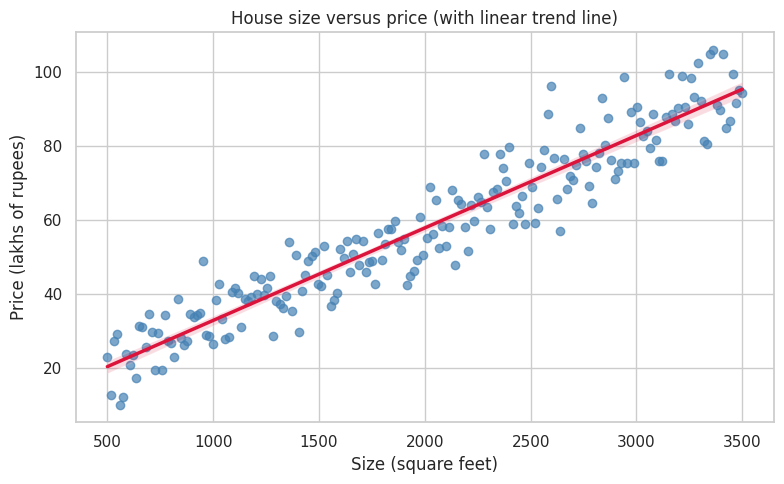

In [76]:
# Bivariate EDA: each dot is one house. The red line is the least-squares trend line.
# This line is for visual exploration; the model is trained properly on the training split in Step 7.
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df,                                             # Use our main spreadsheet data
    x="Size_in_SqFt",                                    # Assigns the 'Size' column from the spreadsheet
    y="Price_in_Lakhs",                                  # Assigns the 'Price' column from the spreadsheet
    scatter_kws={"alpha": 0.7, "color": "steelblue"},    # Make the dots bluish-grey and slightly see-through
    line_kws={"color": "crimson", "linewidth": 2.5},     # Make the straight line deep red and extra thick

)
plt.title("House size versus price (with linear trend line)")
plt.xlabel("Size (square feet)")      #labels x-axis
plt.ylabel("Price (lakhs of rupees)") #labels y-axis
plt.tight_layout()
plt.show()


#### What we see and what we learn (Step 4.3)

**Observation guide:** After running the chart, describe what the dots actually show. Do they form a rising, roughly straight band, a curved pattern, or a widely scattered cloud? Notice any points that sit far from the trend line. Do not copy example numbers from another run if your chart differs.

**Conclusion:** A clear rising band supports trying linear regression, but the model still needs to be tested on houses it did not train on. If the dots do not show a clear linear pattern, report that honestly rather than forcing a linear model to appear successful.


### Step 4.4 — Bar chart: average price in each size class

**What the code does:** `pd.cut(..., bins=6)` cuts the sizes into 6 equal "size classes" (500 sq ft wide each). Then `groupby` puts the houses into one pile for each class, `mean()` finds the average price in each pile, and a bar chart draws them.

**An everyday picture:** Sorting students by grade and finding each grade's average pocket money.

**Why we need it:** A scatter plot has many dots. Averages in a few classes make the trend easy to read: if the bars climb step by step, the price rises with size.

**How it works (the simple idea):** Group, average, draw. The taller the bar, the higher the average price in that size class.

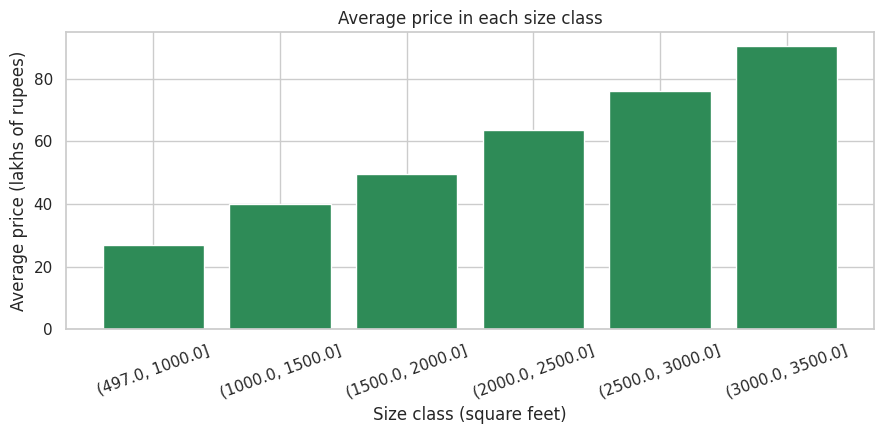

,Price_in_Lakhs
Size_in_SqFt,
"(497.0, 1000.0]",27.04
"(1000.0, 1500.0]",40.04
"(1500.0, 2000.0]",49.64
"(2000.0, 2500.0]",63.56
"(2500.0, 3000.0]",76.05
"(3000.0, 3500.0]",90.26


In [77]:
# Cut the sizes into 6 equal "size classes" and find the average price in each class.
# pd.cut() does the cutting, groupby() puts houses into piles, mean() averages each pile.
size_class = pd.cut(df["Size_in_SqFt"], bins=6)
average_price = df.groupby(size_class, observed=True)["Price_in_Lakhs"].mean()

plt.figure(figsize=(9, 4.5))
#Using the group names for the bottom, the average prices for the height, and color theme green
plt.bar([str(interval) for interval in average_price.index], average_price.values, color="seagreen")
plt.title("Average price in each size class")
plt.xlabel("Size class (square feet)")
plt.ylabel("Average price (lakhs of rupees)")
plt.xticks(rotation=20) # Tilting the bottom labels by 20 degrees so the text doesn't overlap and get messy
plt.tight_layout()
plt.show()

# Print the numbers behind the bars.
display(average_price.round(2))

#### What we see and what we learn (Step 4.4)

**Observation:** The bars climb like a staircase. The average price is **27.04** lakh for houses of 500 to 1,000 sq ft, then **40.04**, **49.64**, **63.56**, **76.05**, and finally **90.26** lakh for houses of 3,000 to 3,500 sq ft. Each step up in size (500 sq ft) adds roughly 10 to 14 lakh.

**Conclusion:** The staircase confirms the rising pattern. Because every step adds roughly the same amount, a straight line is a good description. Next we measure how strong the link is with a single number.

### Step 4.5 — Correlation and heatmap: how strongly are size and price linked?

**What the code does:** `.corr()` computes the *correlation* between size and price. Correlation is a number from −1 to 1:
- near **1**: when one goes up, the other goes up too,
- near **0**: they are not connected,
- near **−1**: when one goes up, the other goes down.

`sns.heatmap` then colours a square for each pair of columns (red for a strong positive link) and writes the number inside.

**An everyday picture:** Ice-cream sales and hot weather move together (near 1). Ice-cream sales and the pages in your homework do not (near 0).

**Why we need it:** It turns the picture into one clear score, so we can say how strong the link is.

**How it works (the simple idea):** The computer checks whether the houses that are bigger than average also tend to be pricier than average. The more often that is true, the closer the number is to 1.

Correlation between size and price: 0.952


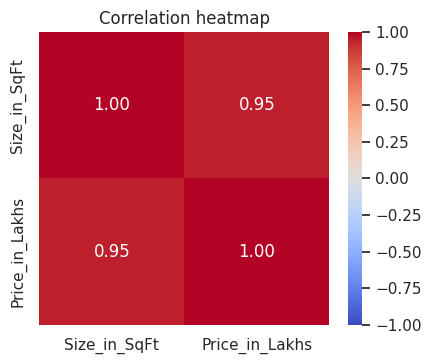

In [78]:
# Correlation is a number from -1 to 1 that says how closely two columns move together:
# close to 1 -> when one goes up, the other goes up too; close to 0 -> not connected; close to -1 -> opposite.
correlation = df["Size_in_SqFt"].corr(df["Price_in_Lakhs"])
print(f"Correlation between size and price: {correlation:.3f}")#Printing + rounding it to 3 decimal places

# A heatmap colours each square by its correlation (red = strongly together, blue = opposite).
plt.figure(figsize=(4.5, 3.8))

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
#df.corr()--> calculate the relationship scores for every single column in spreadsheet against every other column.
#annot=True--> write the math scores directly inside the colored boxes.
#fmt=".2f" ensures the numbers written inside those boxes are rounded to 2 decimal places.
#vmin=-1, vmax=1 sets the strict rules for the colors, telling the computer that the absolute bluest blue is at -1, and the absolute reddest red is at 1.

plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

#### What we see and what we learn (Step 4.5)

**Observation:** Read the correlation printed by the code. A value close to `+1` indicates a strong positive linear association; a value near `0` indicates a weak linear association; a value close to `-1` indicates a strong negative linear association. Use the number from your run, not a hard-coded example.

**Conclusion:** Correlation is useful alongside the scatter plot, but it does not prove causation and does not replace test-set evaluation.


### Step 4.6 — Pair plot: everything at once

**What the code does:** `sns.pairplot(df)` draws a grid of small charts for every pair of columns. On the diagonal each column gets its own histogram. In the other two squares, the two columns are plotted against each other (the same scatter plot twice, once with the columns swapped).

**An everyday picture:** A sports table that shows every team playing every other team on one page.

**Why we need it:** With more columns it would show all the relationships at a glance. Here, with only two columns, it works as a neat one-page summary of Steps 4.1 and 4.3.

**How it works (the simple idea):** The computer loops over every pair of columns and draws the right kind of chart for each.

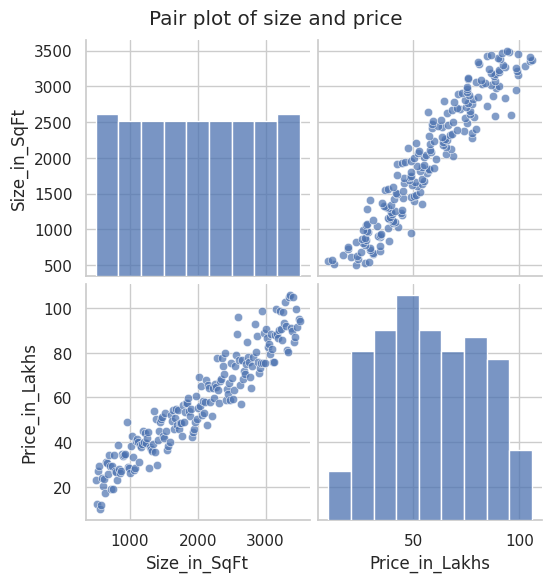

In [79]:
# A pair plot draws a picture for every pair of columns in one grid.
# On the diagonal each column gets its own histogram; the other squares plot one column against the other.
#plot_kws --> make the dots inside the charts slightly see-through (0.7 out of 1.0). When dots are slightly see-through, overlapping dots look darker, helping you spot crowded areas.
grid = sns.pairplot(df, height=2.8, plot_kws={"alpha": 0.7})
grid.figure.suptitle("Pair plot of size and price", y=1.03) #y = 1.03 --> to push up the title silghtly
plt.show()

#### What we see and what we learn (Step 4.6)

**Observation:** The top-left histogram (size) is flat and the bottom-right histogram (price) is a hump, as before. The two other squares show the same rising band of dots, once with size on the bottom and once with price on the bottom.

**Conclusion:** Everything we learned in Step 4 agrees: sizes are evenly spread, prices bunch in the middle, and price rises with size along a rough straight line. We are ready to build the model.

## Step 5 — Separate the clue (`X`) and the answer (`y`)

**What the code does:** It makes two variables:
- `X` holds the *feature* (the clue the model is allowed to look at). Here it is the size column.
- `y` holds the *target* (the right answer we want it to guess). Here it is the price column.
Then it prints each one's `shape`, which is *(number of rows, number of columns)*.

**An everyday picture:** Flash cards. The question is on the front (`X`) and the answer is on the back (`y`). To learn, you look at the question, guess, and then check the back.

**Why we need it:** The model must know which column to learn *from* and which one to learn *to guess*. If we mixed them up, it would be like giving the answer as the question.

**How it works (the simple idea):** We just pick columns out of `df`. The double brackets `[["Size_in_SqFt"]]` keep `X` as a one-column *table*, while the single brackets `["Price_in_Lakhs"]` make `y` a simple list of numbers.

In [80]:
# X = the clue the model may look at: only the size column (double brackets keep it a table).
X = df[["Size_in_SqFt"]]

# y = the right answer we want the model to guess: the price column.
y = df["Price_in_Lakhs"]

# shape = (rows, columns). A simple list only shows (rows,).
print("Input data (X) shape:", X.shape) #The .shape command acts like a measuring tape, it measure our X table and print its dimensions (which will show 200 rows and 1 column).
print("Target data (y) shape:", y.shape)

Input data (X) shape: (200, 1)
Target data (y) shape: (200,)


#### What we see and what we learn (Step 5)

**Observation:** `X` should have one column for the size feature, while `y` should contain one target value per row. Check that their row counts match.

**Conclusion:** The feature and target are aligned. The model must not be given the target column as an input feature.


## Step 6 — Split into a practice set and an exam set

**What the code does:** `train_test_split` shuffles the 200 houses and cuts them into two groups:
- **Training data** (80%): the houses the model studies.
- **Testing data** (20%): houses kept hidden until it is time to check the model's work.
It gives us four boxes: `X_train` and `y_train` (clues and answers for studying), and `X_test` and `y_test` (clues and answers for the exam).

**An everyday picture:** A teacher gives you practice questions to learn from and keeps *different* questions for the real exam. If the exam used the very same questions you practised, a high mark would only prove you remembered the answers.

**Why we need it:** We want to know how well the model guesses the price of houses it has *never seen*. Only unseen houses can tell us that.

**How it works (the simple idea):** The houses are shuffled like a deck of cards, then 80% go to training and 20% to testing. `random_state=42` is like fixing the shuffle so we get the same split every time. `sklearn` (short for scikit-learn) is a library full of ready-made machine-learning tools.

In [81]:
# scikit-learn (sklearn) is a library full of ready-made machine-learning tools.
from sklearn.model_selection import train_test_split

# One line makes four boxes: clues for studying, clues for the exam, answers for studying, answers for the exam.
# test_size=0.20 sends 20% of the rows to the exam box; random_state=42 makes the shuffle repeatable.
X_train, X_test, y_train, y_test = train_test_split(
    X,                     # The complete list of clues (sizes)
    y,                     # The complete list of answers (prices)
    test_size=0.20,        # Put exactly 20% of the houses into the exam pile, leaving 80% for practice
    random_state=42        # Lock the shuffling pattern so it shuffles the exact same way every time we run it
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 160
Testing examples: 40


#### What we see and what we learn (Step 6)

**Observation:** With `test_size=0.20`, the split reserves 20% of the rows for testing and uses the remaining 80% for training. The exact counts depend on the number of rows in your CSV.

**Conclusion:** Keep the test set out of model fitting. It is reserved for an honest estimate of performance on unseen rows.


## Step 7 — Train a scikit-learn pipeline to draw the line

**What the code does:**
1. `LinearRegression()` creates the regression estimator.
2. `Pipeline(...)` packages the estimator into a reusable modeling workflow.
3. `model.fit(X_train, y_train)` learns the line using training houses only.
4. `model.predict(...)` later uses the fitted pipeline to estimate prices.
5. The slope and intercept are read from `model.named_steps["linear_regression"]`.

**An everyday picture:** The training set is the practice paper. The pipeline is the repeatable procedure the student follows to learn the rule; the test set is kept separate to check whether the rule generalizes.

**Why we need it:** This is the modeling stage, not just EDA. It connects the input feature (`Size_in_SqFt`) to the target (`Price_in_Lakhs`) and learns a line by minimizing the sum of squared training errors.

**Beginner pseudocode:**

```text
load the CSV
X = house size; y = house price
split X and y into training and testing sets
create a scikit-learn Pipeline containing LinearRegression
fit the pipeline on X_train and y_train
predict prices for X_test
calculate MAE, RMSE and R² using y_test and predictions
inspect residuals and compare against a baseline
```

The following cells implement these steps in executable Python.


In [82]:
# Import the estimator and Pipeline tools from scikit-learn.
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# This creates our actual empty assembly line and names it model. The steps=[("linear_regression", LinearRegression())] part places our line-drawing tool onto the belt and gives it a nametag so we can easily find it later.
model = Pipeline(steps=[
    ("linear_regression", LinearRegression())
])

# fit = learn the relationship using TRAINING data only.
model.fit(X_train, y_train)

#This line reaches inside the pipe line assembly using the nametag we created earlier and grabs the tool so we can inspect it.
fitted_regressor = model.named_steps["linear_regression"]
coefficient = fitted_regressor.coef_[0]                   #Pull out the "slope" (how much the price increases for every extra square foot).
intercept = fitted_regressor.intercept_                   #Pull out the "intercept" (the baseline starting number for the math equation).

print("Model training completed!")

# Print the slope and intercept numbers it learned, rounded to 4 decimal places.
print(f"Learned coefficient (slope): {coefficient:.4f}")
print(f"Learned intercept: {intercept:.4f}")

# Print the final, complete mathematical rule the computer created to guess future prices.
print(f"Model equation: Predicted Price (lakhs) = ({coefficient:.4f} x Size_in_SqFt) + {intercept:.4f}")


Model training completed!
Learned coefficient (slope): 0.0252
Learned intercept: 7.5530
Model equation: Predicted Price (lakhs) = (0.0252 x Size_in_SqFt) + 7.5530


#### What we see and what we learn (Step 7)

**Observation:** Use the printed slope and intercept to write the learned equation. The slope is the model's estimated change in price (lakhs) per additional square foot. The intercept is the mathematical prediction at size zero; that may not have a practical real-estate interpretation.

**Conclusion:** Training has produced a line, but a plausible-looking equation is not enough. Evaluate it on the held-out test set in Step 8.


## Step 8 — Grade the model with the exam set

Now we ask the model to guess prices for the 40 exam houses it has never seen, and we compare its guesses with the real prices.

### Step 8.1 — Look at some guesses

**What the code does:** `model.predict(X_test)` returns a guess for each exam house, stored in `y_pred`. We then place size, real price, guessed price and the *miss* (real price minus guess) side by side in a small table and show the first 8 rows.

**An everyday picture:** After a guessing game you write the real answer next to each guess.

**Why we need it:** Before using summary scores, it is good to look at real examples with our own eyes.

**How it works (the simple idea):** For each size, the model plugs the size into its rule *price = slope × size + intercept*.

In [83]:
# y_pred = the model's guesses for the 40 exam houses. It has never seen their real prices.
y_pred = model.predict(X_test)

# Put size, real price and guessed price side by side for the first 8 exam houses.
comparison = pd.DataFrame({
    "Size_in_SqFt": X_test["Size_in_SqFt"].values,         # Column 1: The exam clues (house sizes)
    "Real_price": y_test.values,                           # Column 2: The actual hidden answers (real prices)
    "Guessed_price": y_pred.round(2),                      # Column 3: The computer's guesses (rounded to 2 decimal points)

})
# Add a fourth column called "Miss" to calculate exactly how far off each guess was (Real Price minus Guessed Price).
comparison["Miss"] = (comparison["Real_price"] - comparison["Guessed_price"]).round(2)
# Show only the top 8 rows of this scorecard on the screen.
display(comparison.head(8))

,Size_in_SqFt,Real_price,Guessed_price,Miss
0,1932,44.73,56.31,-11.58
1,726,19.28,25.87,-6.59
2,952,48.94,31.58,17.36
3,2882,76.05,80.28,-4.23
4,2430,63.62,68.87,-5.25
5,2234,59.61,63.93,-4.32
6,1540,44.97,46.41,-1.44
7,3063,79.33,84.84,-5.51


#### What we see and what we learn (Step 8.1)

**Observation:** Compare the actual price, predicted price and miss for the displayed test rows. A positive miss (`actual − predicted`) means the model predicted too low; a negative miss means it predicted too high. The size of the miss depends on the dataset and split.

**Conclusion:** Individual examples show how the model behaves, but use summary metrics as well to assess the overall error.


### Step 8.2 — Three scores

**What the code does:** We calculate three scores:
- **MAE** (Mean Absolute Error): the average size of the miss, no matter whether the guess was too high or too low. Smaller is better.
- **RMSE** (Root Mean Squared Error): like MAE, but big misses count extra. The square root (`np.sqrt`) puts the number back into lakhs. Smaller is better.
- **R²** (R-squared): 1 means perfect and 0 means "no better than always guessing the average price".

**An everyday picture:** Throwing darts at a target. MAE is how far, on average, your darts land from the bullseye.

**Why we need it:** One number per score is easier to compare than 40 separate misses.

**How it works (the simple idea):** The computer subtracts each guess from the real price and then averages those misses in three different ways.

In [84]:
# Ready-made "scorekeepers" that measure how far off the guesses are.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# MAE: the average miss, ignoring direction.
mae = mean_absolute_error(y_test, y_pred)
# RMSE: like MAE, but big misses count extra. The square root puts the number back into lakhs.
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
# R squared: 1 = perfect, 0 = no better than always guessing the average.
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R-squared score: {r2:.4f}")

Mean Absolute Error (MAE): 5.81
Root Mean Squared Error (RMSE): 6.88
R-squared score: 0.8783


#### What we see and what we learn (Step 8.2)

**Observation:** Read the MAE, RMSE and R² values printed above. MAE and RMSE are in lakhs of rupees, and lower is generally better. R² compares the model with a mean-based reference; it can be negative on poor test predictions and is not literally the percentage of each individual price caused by size.

**Conclusion:** Report the actual test metrics from your run. Do not describe the model as “good” without considering the error scale, baseline comparison and whether the dataset represents the intended real-world task.


### Step 8.3 — Compare with a "lazy" guesser

**What the code does:** `np.full(...)` makes a list in which every guess is the same: the average training price. We then calculate the MAE of this lazy guesser and print it next to our model's MAE.

**An everyday picture:** A classmate who answers "about 58" to every price question without even looking at the house. Is our model really better than that classmate?

**Why we need it:** A score only means something when we compare it with a simple baseline (a basic reference to beat). If the model could not beat the lazy guesser, it would be useless.

**How it works (the simple idea):** Same scoring method, but with a guess that ignores the size.

In [85]:
# For comparison: what if we ALWAYS guessed the average training price, whatever the size?
# Create a list of guesses made by a "lazy" person who just guesses the average practice price for every single exam house.
lazy_guess = np.full(len(y_test), y_train.mean())

# Grade the lazy person's exam by calculating their average mistake (MAE).
lazy_mae = mean_absolute_error(y_test, lazy_guess)

# Print the lazy person's final grade on the screen so we can see how bad they did.
print(f"Always guessing the average price ({y_train.mean():.2f} lakh) -> MAE: {lazy_mae:.2f}")

# Print our trained computer's final grade right underneath it for a side-by-side comparison.
print(f"Our model                                       -> MAE: {mae:.2f}")

Always guessing the average price (57.86 lakh) -> MAE: 16.96
Our model                                       -> MAE: 5.81


#### What we see and what we learn (Step 8.3)

**Observation:** Compare the baseline MAE with the regression model's MAE. A lower model MAE means size helped on this particular test split; a higher MAE means the model did not beat the simple baseline on that measure.

**Conclusion:** A baseline comparison is a useful sanity check, not proof that the model will perform equally well on real housing data.


### Step 8.4 — Practice versus exam

**What the code does:** We calculate R² twice: once on the 160 training houses (the practice questions) and once on the 40 testing houses (the exam).

**An everyday picture:** A student who scores 91 on the practice paper and 88 on the real exam has really learned. A student who scores 100 on practice but 40 on the exam only memorised the answers.

**Why we need it:** Memorising instead of understanding is called *overfitting*. Comparing the two scores shows whether this happened.

**How it works (the simple idea):** Same R² score, calculated on two different groups of houses.

In [86]:
# Is the model just as good on houses it studied (training) as on houses it never saw (testing)?

# Re-test the computer on the exact same practice questions it already studied.
train_r2 = r2_score(y_train, model.predict(X_train))

# Grade the computer on the hidden exam questions it has never seen before.
test_r2 = r2_score(y_test, y_pred)

# Print the practice quiz score on the screen.
print(f"R-squared on training houses: {train_r2:.4f}")

# Print the final exam score on the screen right below it.
print(f"R-squared on testing houses:  {test_r2:.4f}")

R-squared on training houses: 0.9109
R-squared on testing houses:  0.8783


#### What we see and what we learn (Step 8.4)

**Observation:** Compare the training R² and test R² printed above. A much higher training score than test score can indicate overfitting or a test set that differs from the training data. Similar scores are reassuring, but they do not by themselves prove that the model is reliable.

**Conclusion:** Judge generalization using the held-out test results and the residual plots together.


## Step 9 — Pictures of the model's results

### Step 9.1 — Actual price against predicted price

**What the code does:** It draws a scatter plot where each dot is one exam house: sideways is the real price and upwards is the guessed price. The dashed diagonal line marks "perfect guesses", where the guess equals the real price. (`lower_limit` and `upper_limit` make sure the dashed line covers all dots.)

**An everyday picture:** A dartboard. A dot on the dashed line is a bullseye, and the further a dot is from the line, the bigger the miss.

**Why we need it:** A picture shows at once whether the guesses follow the real prices.

**How it works (the simple idea):** For every exam house the chart puts a dot at (real price, guessed price).

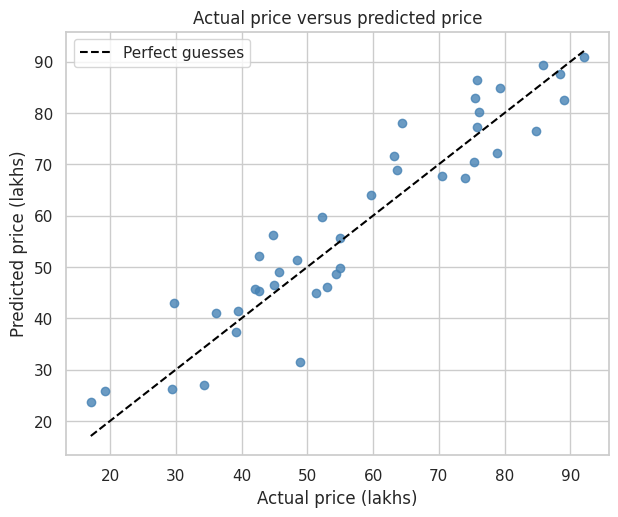

In [87]:
# Each dot is one exam house: sideways = real price, upwards = the model's guess.
plt.figure(figsize=(7, 5.5))
plt.scatter(y_test, y_pred, alpha=0.8, color="steelblue")

# The dashed diagonal line marks "perfect guesses" (guess = real price).

# Find the absolute lowest price (either real or guessed) to know where to start the dashed line.
lower_limit = min(y_test.min(), y_pred.min())

# Find the absolute highest price (either real or guessed) to know where to end the dashed line.
upper_limit = max(y_test.max(), y_pred.max())

# Draw a black, dashed diagonal line from the bottom-left to the top-right to represent a "perfect score".
plt.plot([lower_limit, upper_limit], [lower_limit, upper_limit], linestyle="--", color="black", label="Perfect guesses")

plt.title("Actual price versus predicted price")
plt.xlabel("Actual price (lakhs)")
plt.ylabel("Predicted price (lakhs)")

# Turn on the little map key (legend) so people know what the dashed line means.
plt.legend()
plt.show()

#### What we see and what we learn (Step 9.1)

**Observation:** The dots follow the dashed diagonal quite well: houses that really cost little got low guesses, and expensive houses got high guesses. Most dots sit within a few lakh of the line, but a few are farther away. One dot is clearly far below the line (real price near 49, guessed near 32).

**Conclusion:** The model follows the real prices well, with some misses. That agrees with the scores. Next we see the model's line on top of the houses.

### Step 9.2 — The learned line on top of the houses

**What the code does:** It draws the training houses (blue dots), the exam houses (orange dots) and the model's line (red). To draw the line, `np.linspace` picks 100 evenly spaced sizes from the smallest to the biggest, the model guesses a price for each, and `plt.plot` joins them.

**An everyday picture:** Laying a ruler on a sheet covered with dots to see whether the ruler follows them.

**Why we need it:** In Step 7 we saw the line only as two numbers. Here we see where it sits among the real houses.

**How it works (the simple idea):** A straight line needs only two numbers (where it starts and how steep it is), so asking the model for 100 prices and joining them draws the whole line.

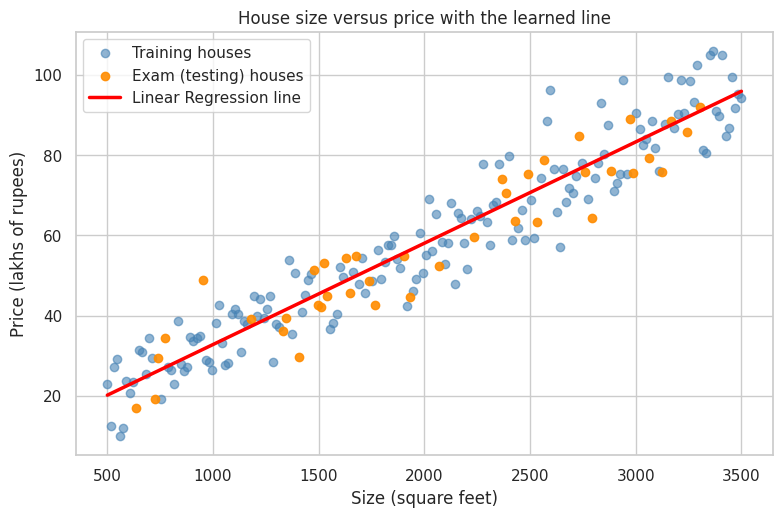

In [88]:
# Show the training houses, the exam houses, and the straight line the model learned.
plt.figure(figsize=(9, 5.5))
plt.scatter(X_train["Size_in_SqFt"], y_train, alpha=0.6, color="steelblue", label="Training houses")
plt.scatter(X_test["Size_in_SqFt"], y_test, alpha=0.9, color="darkorange", label="Exam (testing) houses")

# Pick 100 evenly spaced house sizes, from the absolute smallest to the absolute biggest.
size_values = np.linspace(df["Size_in_SqFt"].min(), df["Size_in_SqFt"].max(), 100)

# Ask our trained computer to guess the price for all 100 of those sizes.
line_prices = model.predict(pd.DataFrame({"Size_in_SqFt": size_values}))

# Connect those 100 guesses together into a thick, solid red line across the chart.
plt.plot(size_values, line_prices, color="red", linewidth=2.5, label="Linear Regression line")

plt.title("House size versus price with the learned line")
plt.xlabel("Size (square feet)")
plt.ylabel("Price (lakhs of rupees)")
plt.legend()
plt.show()

#### What we see and what we learn (Step 9.2)

**Observation:** The red line runs through the middle of the cloud of dots. It starts at about 20 lakh for 500 sq ft and rises to about 96 lakh at 3,500 sq ft. The orange exam houses are mixed in with the blue training houses and lie around the same line.

**Conclusion:** The line fits the pattern of the data well, and the exam houses behave like the practice houses. That is why the test score was good.

### Step 9.3 — Picturing the mistakes

**What the code does:** For every exam house it works out `errors = y_test - y_pred` (real price minus guessed price). Data scientists also call this a *residual*. A positive error means the guess was too low, and a negative error means it was too high. The left chart is a histogram of the errors, and the right chart plots each error against the size of the house, with a dashed line at zero (no error).

**An everyday picture:** After the guessing game, you write down how far off each guess was ("too high by 5", "too low by 3") and look at the whole list.

**Why we need it:** The scores gave one number. This shows every mistake, and tells us whether the model is worse for small or for big houses.

**How it works (the simple idea):** Subtract the guess from the real price for each exam house, then draw the results.

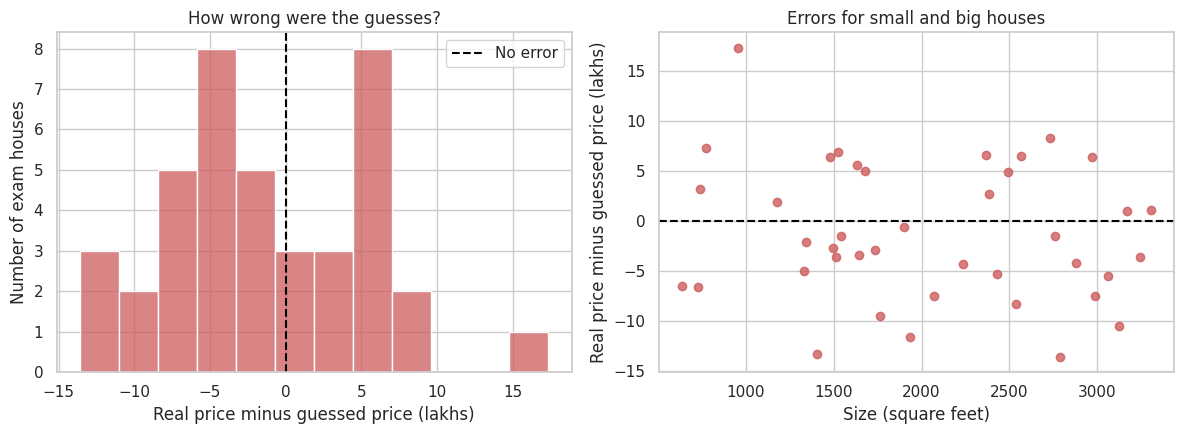

In [89]:
# The error (residual) of each exam house = real price minus the model's guess.
# Positive = guess too LOW; negative = guess too HIGH.

# Calculate the exact mistake for every single exam house (Real Price minus the Guessed Price).
errors = y_test - y_pred

# Set up a large blank canvas with 1 row and 2 side-by-side picture frames for the artist.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: how big were the errors?

# Draw a bar chart sorting the mistakes into 12 buckets, colored dull red.
sns.histplot(errors, bins=12, color="indianred", ax=axes[0])

# Draw a black dashed vertical line straight down the middle at the "0" mark to show a perfect guess.
axes[0].axvline(0, color="black", linestyle="--", label="No error")

# Write the title and labels for the left chart so people know what the bars mean.
axes[0].set_title("How wrong were the guesses?")
axes[0].set_xlabel("Real price minus guessed price (lakhs)")
axes[0].set_ylabel("Number of exam houses")
axes[0].legend()

# Right: do the errors change with house size?

# Draw a dot for each house: sideways is the house size, upwards is how big the mistake was.
axes[1].scatter(X_test["Size_in_SqFt"], errors, color="indianred", alpha=0.8)

# Draw a black dashed horizontal line straight across the "0" mark to show a perfect guess.
axes[1].axhline(0, color="black", linestyle="--")

# Write the title and labels for the right chart so people know what the dots mean.
axes[1].set_title("Errors for small and big houses")
axes[1].set_xlabel("Size (square feet)")
axes[1].set_ylabel("Real price minus guessed price (lakhs)")

plt.tight_layout()
plt.show()

#### What we see and what we learn (Step 9.3)

**Observation:** Check whether residuals are roughly centered around zero and whether they form a pattern, curve, or fan as house size changes. Residuals should not be described as random unless the plotted points support that interpretation.

**Conclusion:** Patterns in residuals can indicate that a straight-line model is missing structure. A flat cloud is more consistent with the assumptions of a simple linear model, though it is not a guarantee of future accuracy.


### Step 9.4 — Errors against the guessed price

**What the code does:** It draws each exam house as a dot. Sideways is the price the model *guessed* (the *fitted* or *predicted* value), upwards is the error (real price minus guessed price). A dashed line marks zero error.

**An everyday picture:** A bathroom scale that is perfectly fair is just as likely to be a little high as a little low, whether you weigh a child or an adult. If it read too high only for heavy people, you would know something is wrong with it.

**Why we need it:** Step 9.3 compared errors with the *size*. This plot compares them with the *guess*. For a good model the dots form a flat, shapeless cloud around zero. A curve or a funnel shape would tell us the model is missing something.

**How it works (the simple idea):** Use `y_pred` for the sideways axis and `errors` (from Step 9.3) for the upward axis.

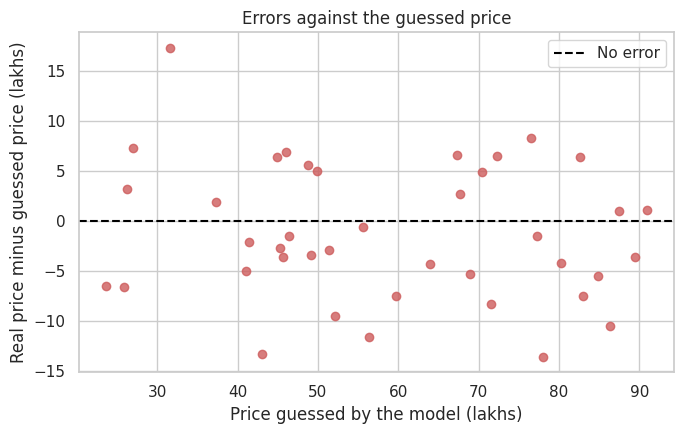

In [90]:
# Errors (residuals) against the model's guesses.
# A healthy model gives a flat, shapeless cloud of dots around the zero line.
plt.figure(figsize=(7, 4.5))

# Draw a dot for every house: sideways position is the computer's guessed price, upwards position is how big the mistake was.
plt.scatter(y_pred, errors, color="indianred", alpha=0.8)

# Draw a black dashed horizontal line straight across the "0" mark to show a perfect guess.
plt.axhline(0, color="black", linestyle="--", label="No error")
plt.title("Errors against the guessed price")
plt.xlabel("Price guessed by the model (lakhs)")
plt.ylabel("Real price minus guessed price (lakhs)")
plt.legend()
plt.tight_layout()
plt.show()

#### What we see and what we learn (Step 9.4)

**Observation:** The dots sit above and below the zero line across the whole range of guessed prices. We should see **no curve** (a bend would mean a straight line is too simple) and **no funnel** (a funnel would mean the errors grow for expensive houses).

**Conclusion:** A flat, shapeless cloud means the model's mistakes do not depend on how expensive the house is. This agrees with what we saw in Step 9.3.

### Step 9.5 — QQ plot: are the errors "normal"?

**What the code does:** It draws a *QQ plot* (quantile-quantile plot) of the errors. Each dot is one exam house. Sideways is where that error *would* sit if errors followed the ideal bell curve (the *normal distribution*), upwards is where it really sits. The red line is the "perfect bell curve" line.

**An everyday picture:** Lining up children by height and comparing each child with the height a "perfectly typical" class would have in that same position. If the real class matches, the pairs fall on a straight line.

**Why we need it:** Linear regression works best when the leftover errors are random wobble that follows a bell curve. The QQ plot checks this much more clearly than a histogram, especially with only 40 houses.

**How it works (the simple idea):** The computer sorts the errors from smallest to biggest, works out the matching positions on a perfect bell curve, and plots one against the other. Dots close to the line mean the errors are close to normal.

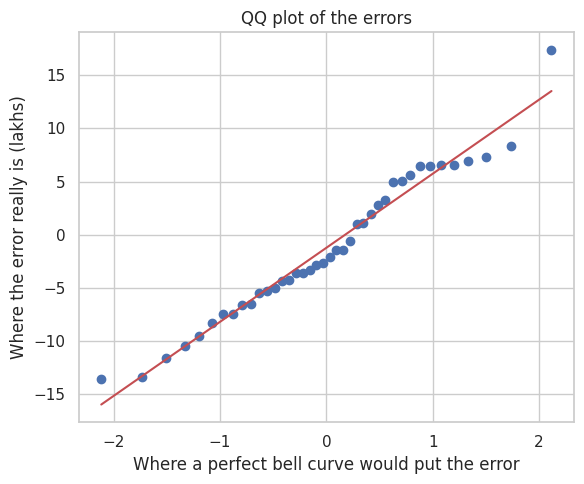

In [91]:
# QQ plot of the errors. scipy is a maths library; probplot sorts the errors and
# compares them with the values a perfect bell curve (normal distribution) would give.

# Go into a special "Advanced Math Toolbox" called scipy and fetch the stats tool.
from scipy import stats

plt.figure(figsize=(6, 5))

# Use the math tool to sort all the computer's mistakes, compare them against a "perfect bell curve", and draw the dots.
stats.probplot(errors, dist="norm", plot=plt)

plt.title("QQ plot of the errors")
plt.xlabel("Where a perfect bell curve would put the error")
plt.ylabel("Where the error really is (lakhs)")
plt.tight_layout()
plt.show()

#### What we see and what we learn (Step 9.5)

**Observation:** The dots should hug the red line through the middle. Small bends at the two far ends are normal when there are only 40 houses. Dots that curve far away from the line would mean the errors are skewed or have extreme values.

**Conclusion:** If the dots follow the line, the errors behave like ordinary random wobble, which is exactly what linear regression expects. Together with Steps 9.3 and 9.4, this supports trusting the model's line.

### Step 9.6 — Learning curve: would more houses help?

**What the code does:** It trains the model again and again on bigger and bigger piles of houses (from a small pile up to all 200). Each time it checks the score (R²) on the training pile and on houses that were held back. It then draws both scores against the number of houses. The shaded bands show how much the scores moved between the repeats.

**An everyday picture:** A student practising with 5 questions, then 20, then 100, and being tested each time. We watch whether more practice still helps, or whether the student has already learned all that this method can teach.

**Why we need it:** It answers two questions. Is the model too simple (*underfitting*: both scores stay low)? Is it memorising (*overfitting*: training score high, exam score far lower)? It also shows whether collecting more data would be worth the effort.

**How it works (the simple idea):** `learning_curve` splits the data 5 different ways (called *cross-validation*), trains on growing portions, and returns the scores for each portion.

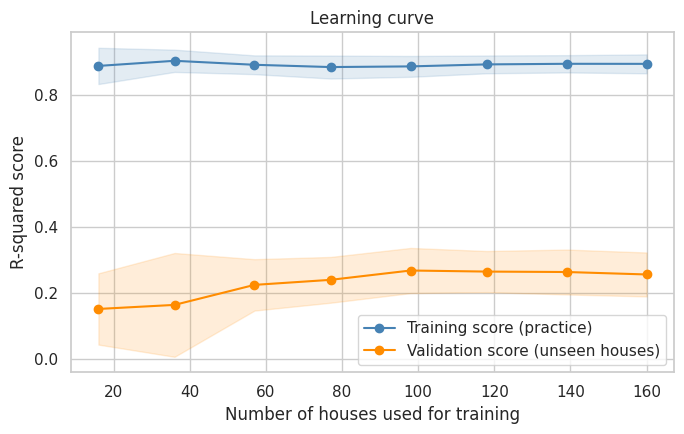

In [98]:
# Fetch a special testing tool to see if studying more houses makes the computer smarter.
from sklearn.model_selection import learning_curve

# Fetch our trusty line-drawing math tool again.
from sklearn.linear_model import LinearRegression

# Run a massive experiment: teach the computer again and again using growing piles of flashcards.
sizes, train_scores, valid_scores = learning_curve(
    LinearRegression(), X, y,               # The math tool, our clues (sizes), and our answers (prices).
    train_sizes=np.linspace(0.1, 1.0, 8),   # Start by letting it study just 10% of the cards, then 20%, up to 100% in 8 steps.
    cv=5,                                   # To be perfectly fair, repeat every single step 5 times with a different shuffle.
    scoring="r2",                           # Grade the tests using the R-squared scale (where 1 is a perfect score).
    shuffle=True, random_state=42,          # Shuffle the cards before dealing, and lock the shuffle pattern.
)

# For the practice quizzes, average the 5 grades together and calculate how much the grades "wobbled" up and down.
train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)

# For the hidden final exams, average the 5 grades together and calculate the wobble.
valid_mean, valid_std = valid_scores.mean(axis=1), valid_scores.std(axis=1)

# Set up a blank canvas that is 7 units wide and 4.5 units tall.
plt.figure(figsize=(7, 4.5))

# Draw the practice scores as a blue line with dots on it.
plt.plot(sizes, train_mean, "o-", color="steelblue", label="Training score (practice)")

# Paint a faint blue shadow around the blue line to show how much the practice grades wobbled.
plt.fill_between(sizes, train_mean - train_std, train_mean + train_std, color="steelblue", alpha=0.15)

# Draw the hidden exam scores as an orange line with dots on it.
plt.plot(sizes, valid_mean, "o-", color="darkorange", label="Validation score (unseen houses)")

# Paint a faint orange shadow around the orange line to show how much the exam grades wobbled.
plt.fill_between(sizes, valid_mean - valid_std, valid_mean + valid_std, color="darkorange", alpha=0.15)


plt.title("Learning curve")
plt.xlabel("Number of houses used for training")
plt.ylabel("R-squared score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### What we see and what we learn (Step 9.6)

**Observation:** Compare the training and validation learning-curve lines and their spread. Low scores on both can indicate underfitting; a persistent gap can indicate overfitting. If the validation score is already stable, adding more similar data may offer limited improvement, but do not assume this without checking the plotted results.

**Conclusion:** Use the learning curve as diagnostic evidence, not a guarantee. Results depend on the dataset and cross-validation splits.


## Step 10 — Ask the model about new houses

**What the code does:**
1. We make a small table `new_houses` with five sizes: 800, 1,500, 2,500, 3,500 and 5,000 sq ft. The column has the same name as in training (`Size_in_SqFt`).
2. `model.predict(new_houses)` guesses a price for every row at once.
3. We add the guesses as a new column and display the table.

**An everyday picture:** After a student has studied, you ask five new questions and write down the answers.

**Why we need it:** This is what a model is *for*: using what it learned on something new.

**How it works (the simple idea):** The model plugs each size into its rule: *price = (0.0252 × size) + 7.553*.

In [96]:
# Create a tiny, brand-new spreadsheet with 5 imaginary houses we want the computer to price for us.
new_houses = pd.DataFrame({"Size_in_SqFt": [800, 1500, 2500, 3500, 5000]})

# Hand this new list to our fully trained computer and ask it to guess the price for all 5 houses instantly.
new_prices = model.predict(new_houses)

# Add a brand new column to our tiny spreadsheet and paste the computer's guesses into it, rounded like real money.
new_houses["Estimated_Price_in_Lakhs"] = new_prices.round(2)

display(new_houses)

,Size_in_SqFt,Estimated_Price_in_Lakhs
0,800,27.74
1,1500,45.40
2,2500,70.64
3,3500,95.87
4,5000,133.72


#### What we see and what we learn (Step 10)

**Observation:** The table shows the model's estimated price for each requested size. Estimates within the training size range are interpolation; estimates outside that range are extrapolation and are less trustworthy.

**Important limitation:** These are model outputs from a teaching dataset, not real market valuations. Real prices depend on location, age, condition, amenities and other variables that this model does not use.

**Conclusion:** The pipeline can produce predictions, but the quality of those predictions depends on the data and the model's limitations.


## Complete scikit-learn implementation — what is actually covered

This notebook is **not limited to ingestion and EDA**. The runnable cells above and below implement the complete basic regression workflow:

- `train_test_split(...)` creates training and test sets.
- `Pipeline([("linear_regression", LinearRegression())])` defines the estimator workflow.
- `model.fit(X_train, y_train)` learns from training data only.
- `model.predict(X_test)` generates held-out predictions.
- `mean_absolute_error`, `mean_squared_error`/RMSE and `r2_score` evaluate those predictions.
- Baseline comparison, residual charts and a learning curve provide additional diagnostics.
- The final steps predict new sizes and save/reload the fitted pipeline.

**Compact pseudocode for explaining this project aloud:**

```text
Read and validate data
Plot Size_in_SqFt against Price_in_Lakhs; check whether a line is plausible
Set X = size and y = price
Split into training and test sets
Fit a LinearRegression pipeline on training data
Predict test prices
Compare predictions with actual test prices using MAE, RMSE and R²
Inspect residuals; compare with a baseline
Predict new examples and save the fitted model
```

**What this simple project does not establish:** it does not prove that house size alone is sufficient for real Indian housing prices. For a real deployment, collect representative market data, include relevant features, validate data quality, and evaluate on an appropriate holdout set.

---


## Step 11 — Save the trained model

**What the code does:**
1. `import joblib` brings in a tool that can save machine-learning models to a file.
2. `MODEL_DIR` is a folder named `saved_model`, and `mkdir(...)` creates it if it does not exist.
3. `MODEL_PATH` adds the file name `size_price_linear_regression.pkl` to the folder address. (`.pkl` is short for *pickle*, a file type for saved Python objects.)
4. `joblib.dump(model, MODEL_PATH)` writes the trained model into that file.

**An everyday picture:** Saving a video game. You do not have to start again from the beginning, because your progress is stored.

**Why we need it:** Teaching a model takes time, and the Colab computer is temporary. A saved file lets us (or an app) use the trained model later without teaching it again.

**How it works (the simple idea):** This model is really just two learned numbers (the slope and the start of the line). `dump` writes them into the file. The file does not contain the dataset or this notebook.

In [97]:
# Fetch a special tool that knows how to save and load a trained computer "brain".
import joblib

# Decide on a name for a new folder (like a drawer in a filing cabinet) to keep our stuff organized.
MODEL_DIR = Path("saved_model")

# Tell the computer to actually build that folder. If the folder is already there, don't throw an error, just use it.
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Create the exact file name and combine it with the folder to make a complete address.
MODEL_PATH = MODEL_DIR / "size_price_linear_regression.pkl"

# Write all the math rules the computer learned into that file, exactly like saving progress in a video game.
joblib.dump(model, MODEL_PATH)

print("Model saved successfully!")
print("Saved location:", MODEL_PATH)

Model saved successfully!
Saved location: saved_model/size_price_linear_regression.pkl


#### What we see and what we learn (Step 11)

**Observation:** The cell prints "Model saved successfully!" and the location `saved_model/size_price_linear_regression.pkl`.

**Conclusion:** The trained model is stored in a file. If you run this in Google Colab, the file lives on the temporary Colab computer, so download it from the Files panel (or copy it to Google Drive) if you want to keep it after the session ends. One more check remains: does the saved copy work like the original?

## Step 12 — Load the saved model and check it

**What the code does:** `joblib.load(MODEL_PATH)` reads the model back from the file into `loaded_model`. We ask it for the same five prices as in Step 10 and compare them with the original model's answers. `np.allclose` asks "are these two lists of numbers equal, apart from tiny rounding differences?"

**An everyday picture:** After saving a video game, you close it, open the save file and check that you are exactly where you stopped.

**Why we need it:** A save that cannot be opened again is useless. This check proves that the saved model really works.

**How it works (the simple idea):** `load` is the opposite of `dump`: it rebuilds the model from the numbers stored in the file. If the answers are equal, the copy is faithful.

In [99]:
# Fetch the frozen computer "brain" from our file folder and bring it back to life, just like loading a saved video game.
loaded_model = joblib.load(MODEL_PATH)

# Hand this newly loaded computer the exact same list of 5 imaginary house sizes and ask it to guess their prices.
loaded_prices = loaded_model.predict(pd.DataFrame({"Size_in_SqFt": [800, 1500, 2500, 3500, 5000]}))

# Print a friendly message to the screen to confirm the computer woke up properly.
print("Saved model loaded successfully!")


print("Prices from the loaded model: ", loaded_prices.round(2))
print("Prices from the original model:", new_prices.round(2))
print("Are all the answers the same?  ", np.allclose(loaded_prices, new_prices))

Saved model loaded successfully!
Prices from the loaded model:  [ 27.74  45.4   70.64  95.87 133.72]
Prices from the original model: [ 27.74  45.4   70.64  95.87 133.72]
Are all the answers the same?   True


#### What we see and what we learn (Step 12)

**Observation:** The loaded model gives the prices 27.74, 45.4, 70.64, 95.87 and 133.72, exactly the same as the original model, and the check prints `True`.

**Conclusion:** The saved file works exactly like the original model, so it can be used again without teaching it. Saving does not make the model *better*, it only makes it *reusable*.